# Bound vs unbound antibody RMSDs

How far is the unbound antibody of each benchmark case from its bound form? This notebook measures it for
the **16 antibody–antigen cases** of the [Protein–Protein Docking Benchmark 5.5](https://zlab.wenglab.org/benchmark/)
that `array/launch_wf.py` runs, on **the structures the workflow itself docks**, and checks the numbers
against the benchmark's published **I-RMSD**.

The benchmark defines it as:

> The I-RMSD was calculated by superposing the unbound component proteins onto their bound forms, using the
> Cα atoms for residues that had any atom within 10 Å of any atom of the binding partner.

That fixes what the previous version of this notebook swept over: **one interface** (10 Å, any atom, found on
the bound complex), **Cα atoms**, and **both partners**, each fitted on its own interface residues. The
cutoff sweep, the 5 Å interface and the antibody-only stand-in for the I-RMSD are gone.

## Where the structures come from

Every case is prepared by the workflow's own code, from the configuration `launch_wf.py` writes for it
(`output/exploration/rmsds/prep/case_<i>/workflow.yml`):

| step | what | code |
|---|---|---|
| `step0_*` | download: biological assembly 1, unless the identifier names a model | `workflow.download_pdbs` |
| `step1_repair_*` | unbound antibody and antigen: missing residues built by Modeller, observed ones kept (`fix_known`) | `utils.repair_structure` |
| `step1_0`–`step1_6` | cleaning; antibody fused into chain A, antigen into chain B; reference complex A + B | `haddock.prepare_structures` |
| `step2_19` | IMGT numbering of the repaired antibody | ANARCII (`biobb_haddock`) |

The analysis then reuses `haddock_interface` (the interface, here at 10 Å instead of stage 1's 3.9 Å),
`utils.map_contact_residues` (which bound residue is which unbound residue) and `cdr.imgt_region_ri` with
`cdr.CDR_RANGES` / `cdr.FRAMEWORK_RANGES` (the CDRs and the framework, as stage 2 defines them). The few
helpers only this notebook needs are in `ab_rmsds.py`.

As a control, the benchmark's own bound and unbound files (`output/benchmark5.5`) go through the same
steps 1_0–1_6 and the same I-RMSD code.

## What is measured

* **I-RMSD** of both partners, per the definition above, and its antibody and antigen sides.
* **Antibody regions**, Cα only: `fv`, `framework`, `cdr_all`, `H1`–`L3` (IMGT), `full` (every paired residue,
  constant domains included) and `interface` (antibody side of the 10 Å interface), under three superpositions:

| scheme | fitted on | answers |
|---|---|---|
| `self` | the measured atoms | how much the region's own shape changes; a lower bound on the other two |
| `fv_fw` | Fv framework Cα | how far the region moves in the antibody's own frame; the number for CDRs |
| `full` | every paired Cα | the same in a whole-Fab frame, so it also absorbs the elbow angle |

In [1]:
import warnings

import matplotlib.pyplot as plt
import nglview as nv
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from Bio.SeqUtils import seq1
from antibody_wf import utils
import ab_rmsds as ar

for d in (ar.RES, ar.FIG):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid', context='notebook', rc={'grid.color': ar.GRID})
pd.set_option('display.width', 200, 'display.max_columns', 40)

print('cases      :', len(ar.COMPLEXES))
print('structures :', ar.PREP)
print('results    :', ar.RES)
print('figures    :', ar.FIG)

cases      : 16
structures : /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/prep
results    : /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/results
figures    : /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/figures


## 1. Preparing the cases

The first run downloads the entries and runs the Modeller repair, around 10 s per case; afterwards
everything is read from disk (`ar.prepare_case(i, force=True)` redoes a case). `modelled` counts the residues
the repair built, i.e. those whose Cα is not where a Cα of the downloaded entry is.

In [2]:
files, bench_files, modelled = {}, {}, {}
for idx in range(len(ar.COMPLEXES)):
    files[idx] = ar.prepare_case(idx)
    bench_files[idx] = ar.prepare_benchmark_case(idx)
    modelled[idx] = ar.case_modelled(files[idx])

cases = pd.DataFrame([{**ar.case_info(idx), 'antibody_modelled': len(modelled[idx]['A']),
                       'antigen_modelled': len(modelled[idx]['B'])}
                      for idx in files]).set_index('case_idx')
display(cases[['reference', 'antibody', 'antigen', 'benchmark_complex', 'difficulty',
               'antibody_modelled', 'antigen_modelled']])

,reference,antibody,antigen,benchmark_complex,difficulty,antibody_modelled,antigen_modelled
case_idx,,,,,,,
0,2VXT_HL:I,2VXU_HL,1J0S_A,2VXT_HL:I,rigid,0,0
1,2W9E_HL:A,2W9D_HL,1QM1_A,2W9E_HL:A,rigid,0,0
2,3EOA_LH:I,3EO9_LH,3F74_A,3EOA_LH:I,rigid,5,0
3,3HMX_LH:AB,3HMW_LH,1F45_AB,3HMX_LH:AB,rigid,3,69
4,3MXW_LH:A,3MXV_LH,3M1N_A,3MXW_LH:A,rigid,0,0
5,5VPG_CD:A,3RVT_CD,3F5V_A,3RVW_CD:A,rigid,0,1
6,4DN4_LH:M,4DN3_LH,1DOL_A,4DN4_LH:M,rigid,6,0
7,4FQI_HL:ABEFCD,4FQH_HL,2FK0_ABCDEF,4FQI_HL:ABEFCD,rigid,0,0
8,4G6J_HL:A,4G5Z_HL,4I1B_A,4G6J_HL:A,rigid,0,0


## 2. The interface

`haddock_interface` at 10 Å on the bound complex of step1_6 (chain A antibody, chain B antigen). It is
checked against an independent any-atom search, MDAnalysis `around 10`, so the benchmark's "any atom within
10 Å of any atom of the binding partner" is what is used, not assumed.

In [3]:
iface_rows = []
for idx, f in files.items():
    interface = utils.read_interface(f['interface'])
    disagree = ar.interface_check(f['reference'], interface)
    iface_rows.append({'case_idx': idx, 'antibody': len(interface['A']), 'antigen': len(interface['B']),
                       'disagree_with_mdanalysis': sum(map(len, disagree.values()))})
iface = pd.DataFrame(iface_rows).set_index('case_idx')
display(iface.T)
assert iface.disagree_with_mdanalysis.sum() == 0, 'haddock_interface is not the any-atom 10 A interface'
print('haddock_interface lists exactly the residues with any atom within 10 A of the partner, '
      'in all 16 cases')
print(f'interface size: antibody {iface.antibody.min()}-{iface.antibody.max()}, '
      f'antigen {iface.antigen.min()}-{iface.antigen.max()} residues')

case_idx,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
antibody,76,66,51,72,71,50,56,45,71,59,69,69,66,69,49,70
antigen,54,32,43,54,59,50,29,80,55,53,78,55,43,56,27,49
disagree_with_mdanalysis,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


haddock_interface lists exactly the residues with any atom within 10 A of the partner, in all 16 cases
interface size: antibody 45-76, antigen 27-80 residues


## 3. I-RMSD against the published values

Two sets of structures go through the same code:

* **benchmark files** — the benchmark's own `_r_b`, `_l_b`, `_r_u`, `_l_u`. Same complexes, same crystal
  forms (3RVW for the 3RVT case), so they test the definition and the code: they should give the published
  column.
* **workflow** — what stage 1 prepares and HADDOCK3 docks. Where it differs from the benchmark files, the
  difference comes from the preparation: the entry or the model downloaded, the repair, or the residue
  pairing.

`*_ab` and `*_ag` are the antibody and antigen sides of the pooled value.

In [4]:
irm_rows = []
for idx in files:
    bench = ar.irmsd(bench_files[idx])
    ours = ar.irmsd(files[idx], modelled[idx])
    irm_rows.append({'case_idx': idx, **{f'bench_{k}': v for k, v in bench.items()},
                     **{f'wf_{k}': v for k, v in ours.items()}})
irm = cases[['ref_code', 'unb_code', 'difficulty', 'benchmark_irmsd']].join(
    pd.DataFrame(irm_rows).set_index('case_idx'))
irm.to_csv(ar.RES / 'ab_rmsds_irmsd.csv')
display(irm[['ref_code', 'unb_code', 'benchmark_irmsd', 'bench_irmsd', 'bench_irmsd_ab', 'bench_irmsd_ag',
             'wf_irmsd', 'wf_irmsd_ab', 'wf_irmsd_ag']].round(2))

d_bench = irm.bench_irmsd - irm.benchmark_irmsd
d_wf = irm.wf_irmsd - irm.bench_irmsd
print(f'benchmark files - published: |diff| <= 0.01 A in {(d_bench.abs() <= 0.015).sum()}/16, '
      f'largest {d_bench.abs().max():.2f} A ({irm.ref_code[d_bench.abs().idxmax()]})')
print(f'workflow - benchmark files : |diff| <= 0.01 A in {(d_wf.abs() <= 0.015).sum()}/16; differ in')
for idx in d_wf[d_wf.abs() > 0.015].index:
    r = irm.loc[idx]
    print(f'    {r.ref_code}/{r.unb_code}: {r.wf_irmsd:.2f} vs {r.bench_irmsd:.2f} A '
          f'(antibody side {r.wf_irmsd_ab:.2f} vs {r.bench_irmsd_ab:.2f}, '
          f'antigen side {r.wf_irmsd_ag:.2f} vs {r.bench_irmsd_ag:.2f})')
print('interface residues without an unbound counterpart (workflow):',
      int(irm.wf_n_iface_ab_unmapped.sum() + irm.wf_n_iface_ag_unmapped.sum()))
print('interface residues built by the repair (workflow)          :',
      int(irm.wf_n_iface_ab_modelled.sum() + irm.wf_n_iface_ag_modelled.sum()))
assert d_bench.abs().max() < 0.05, 'the benchmark files do not reproduce the published I-RMSD'

,ref_code,unb_code,benchmark_irmsd,bench_irmsd,bench_irmsd_ab,bench_irmsd_ag,wf_irmsd,wf_irmsd_ab,wf_irmsd_ag
case_idx,,,,,,,,,
0,2VXT,2VXU,1.33,1.32,0.38,2.00,1.40,0.38,2.13
1,2W9E,2W9D,1.13,1.13,0.83,1.57,1.13,0.83,1.57
2,3EOA,3EO9,0.39,0.39,0.37,0.42,0.39,0.37,0.42
3,3HMX,3HMW,0.73,0.73,0.55,0.91,0.73,0.55,0.91
4,3MXW,3MXV,0.48,0.48,0.44,0.53,0.48,0.44,0.53
5,5VPG,3RVT,0.50,0.50,0.47,0.53,0.50,0.47,0.53
6,4DN4,4DN3,0.81,0.81,0.96,0.40,0.81,0.96,0.40
7,4FQI,4FQH,1.08,1.08,0.75,1.23,2.13,0.75,2.60
8,4G6J,4G5Z,0.61,0.61,0.39,0.81,0.61,0.39,0.81


benchmark files - published: |diff| <= 0.01 A in 15/16, largest 0.03 A (4G6M)
workflow - benchmark files : |diff| <= 0.01 A in 13/16; differ in
    2VXT/2VXU: 1.40 vs 1.32 A (antibody side 0.38 vs 0.38, antigen side 2.13 vs 2.00)
    4FQI/4FQH: 2.13 vs 1.08 A (antibody side 0.75 vs 0.75, antigen side 2.60 vs 1.23)
    4GXU/4GXV: 8.63 vs 0.78 A (antibody side 0.55 vs 0.55, antigen side 11.84 vs 0.94)
interface residues without an unbound counterpart (workflow): 1
interface residues built by the repair (workflow)          : 0


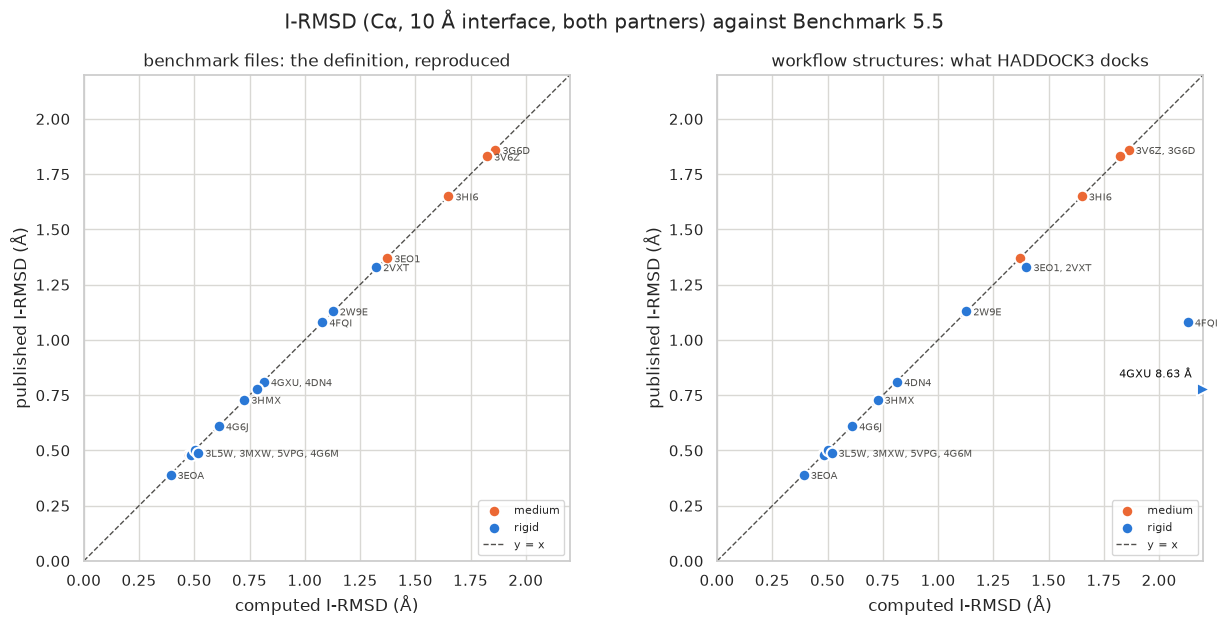

In [5]:
def irmsd_panel(ax, values, title, lim=2.2):
    """Published vs computed I-RMSD; points past `lim` are drawn at the edge with their value."""
    for diff, grp in irm.groupby('difficulty'):
        inside = grp[values[grp.index] <= lim]
        ax.scatter(values[inside.index], inside.benchmark_irmsd, s=70, color=ar.DIFF_COLOR[diff],
                   edgecolor='white', linewidth=1.5, label=diff, zorder=3)
        for idx, row in grp[values[grp.index] > lim].iterrows():
            ax.scatter(lim, row.benchmark_irmsd, s=90, marker='>', color=ar.DIFF_COLOR[diff],
                       edgecolor='white', linewidth=1.5, zorder=3, clip_on=False)
            ax.annotate(f'{row.ref_code} {values[idx]:.2f} Å', (lim, row.benchmark_irmsd), fontsize=8,
                        xytext=(-8, 8), textcoords='offset points', ha='right', color=ar.INK)
    inside = values <= lim
    ar.label_points(ax, values[inside], irm.benchmark_irmsd[inside], irm.ref_code[inside])
    ax.plot([0, lim], [0, lim], ls='--', color=ar.INK_MUTED, lw=1, zorder=1, label='y = x')
    ax.set(xlim=(0, lim), ylim=(0, lim), aspect='equal', title=title,
           xlabel='computed I-RMSD (Å)', ylabel='published I-RMSD (Å)')
    ax.legend(loc='lower right', fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
irmsd_panel(axes[0], irm.bench_irmsd, 'benchmark files: the definition, reproduced')
irmsd_panel(axes[1], irm.wf_irmsd, 'workflow structures: what HADDOCK3 docks')
fig.suptitle('I-RMSD (Cα, 10 Å interface, both partners) against Benchmark 5.5', y=0.99)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig1_irmsd_vs_published.png', dpi=150, bbox_inches='tight')
plt.show()

Which partner carries the I-RMSD? The benchmark value pools both sides, so a case can be "medium" because of
the antigen alone. Benchmark files, so that the workflow's own pairing problems (above) do not enter.

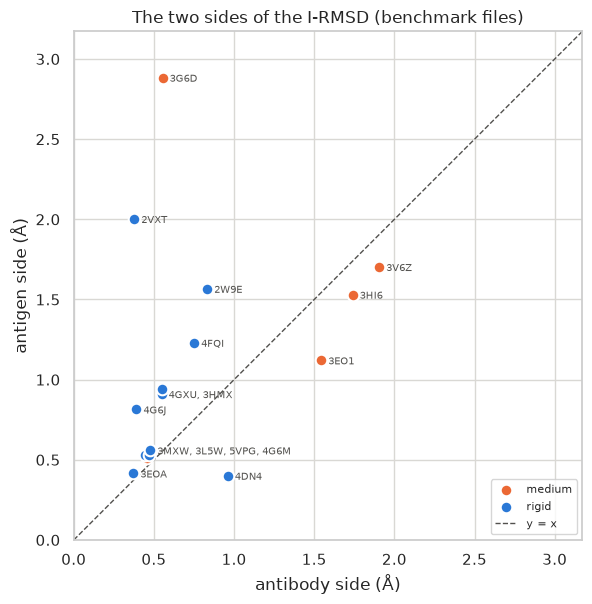

larger side per case: {'antigen': np.int64(12), 'antibody': np.int64(4)}
medium: median antibody side 1.54 A, antigen side 1.53 A
rigid : median antibody side 0.48 A, antigen side 0.81 A


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6.2))
for diff, grp in irm.groupby('difficulty'):
    ax.scatter(grp.bench_irmsd_ab, grp.bench_irmsd_ag, s=70, color=ar.DIFF_COLOR[diff],
               edgecolor='white', linewidth=1.5, label=diff, zorder=3)
ar.label_points(ax, irm.bench_irmsd_ab, irm.bench_irmsd_ag, irm.ref_code)
lim = 1.1 * max(irm.bench_irmsd_ab.max(), irm.bench_irmsd_ag.max())
ax.plot([0, lim], [0, lim], ls='--', color=ar.INK_MUTED, lw=1, zorder=1, label='y = x')
ax.set(xlim=(0, lim), ylim=(0, lim), aspect='equal', xlabel='antibody side (Å)', ylabel='antigen side (Å)',
       title='The two sides of the I-RMSD (benchmark files)')
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig2_irmsd_sides.png', dpi=150, bbox_inches='tight')
plt.show()

side = np.where(irm.bench_irmsd_ag > irm.bench_irmsd_ab, 'antigen', 'antibody')
print('larger side per case:', dict(pd.Series(side).value_counts()))
for diff, grp in irm.groupby('difficulty'):
    print(f'{diff:6s}: median antibody side {grp.bench_irmsd_ab.median():.2f} A, '
          f'antigen side {grp.bench_irmsd_ag.median():.2f} A')

## 4. Antibody regions

The whole bound antibody (chain A of step1_6) is paired with the prepared unbound one by
`utils.map_contact_residues` over every residue. Two kinds of pair are left out rather than trusted:
residues that equally scoring alignments pair differently (a gap next to repeated residues), and pairs that
cross from one antibody chain to the other. The fused chain A hides the light/heavy junction, and in 4DN4 the
alignment paired the light chain's C-terminal Gly with the heavy chain's first Val, 55 Å away.

The regions are defined on the unbound side, from ANARCII's IMGT numbering through `cdr.imgt_region_ri`, and
carried to the bound side by that pairing. The framework is `cdr.FRAMEWORK_RANGES` clipped at IMGT 128, the
end of the V domain: the ranges run to 129, which ANARCII gives to the first CH1/CL residue, a residue that
follows the elbow (7.9 Å off in 3EOA) and would add up to 0.22 Å to the framework RMSD. CDR-L2 is 3 residues
wide in every one of these antibodies, too few for a `self` fit, so it is only measured in a fixed frame.

In [7]:
records, residue_records, ab = [], [], {}
for idx, f in files.items():
    ab[idx] = ar.antibody_rmsds(f, ar.chain_types(idx), modelled[idx]['A'])
    records += [{'case_idx': idx, **row} for row in ab[idx]['rows']]
    residue_records += [{'case_idx': idx, 'ref_code': cases.ref_code[idx], **row}
                        for row in ab[idx]['residues']]
df = pd.DataFrame(records)
dfres = pd.DataFrame(residue_records)
df.to_csv(ar.RES / 'ab_rmsds_long.csv', index=False)
dfres.to_csv(ar.RES / 'ab_rmsds_residues.csv', index=False)

print(f'{len(df)} RMSD rows ({len(ar.EXTENTS)} extents x {len(ar.SCHEMES)} schemes x 16 cases), '
      f'{len(dfres)} residue rows')
print('residues per extent:')
display(df[df.scheme == 'self'].pivot_table(index='case_idx', columns='extent', values='n_res')[ar.EXTENTS].T)
n_bound = {idx: len(ar.read_ca(f['reference'], 'A')) for idx, f in files.items()}
lost = {idx: n_bound[idx] - len(ab[idx]['pairs']) for idx in files}
print('bound antibody residues left unpaired (no counterpart, or ambiguous):', lost)
print('pairs dropped for crossing the light/heavy junction:', {idx: a['n_cross_chain'] for idx, a in ab.items() if a['n_cross_chain']})
print('paired residues the repair built:', {idx: n for idx, n in
      df[(df.extent == 'full') & (df.scheme == 'self')].set_index('case_idx').n_modelled.items() if n})

528 RMSD rows (11 extents x 3 schemes x 16 cases), 6874 residue rows
residues per extent:


case_idx,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
extent,,,,,,,,,,,,,,,,
fv,220.0,222.0,229.0,227.0,227.0,229.0,227.0,230.0,226.0,228.0,236.0,229.0,230.0,225.0,229.0,238.0
framework,180.0,180.0,181.0,181.0,181.0,181.0,179.0,178.0,181.0,181.0,178.0,181.0,180.0,179.0,181.0,181.0
cdr_all,40.0,42.0,48.0,46.0,46.0,48.0,48.0,52.0,45.0,47.0,58.0,48.0,50.0,46.0,48.0,57.0
H1,8.0,8.0,8.0,8.0,8.0,9.0,8.0,8.0,8.0,10.0,8.0,8.0,8.0,8.0,10.0,8.0
H2,8.0,8.0,8.0,8.0,8.0,7.0,8.0,8.0,8.0,7.0,8.0,8.0,8.0,8.0,7.0,8.0
H3,6.0,9.0,14.0,12.0,12.0,14.0,12.0,14.0,11.0,12.0,19.0,13.0,15.0,13.0,13.0,16.0
L1,6.0,5.0,6.0,6.0,6.0,6.0,7.0,8.0,6.0,6.0,8.0,7.0,6.0,6.0,6.0,12.0
L2,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
L3,9.0,9.0,9.0,9.0,9.0,9.0,10.0,11.0,9.0,9.0,12.0,9.0,10.0,8.0,9.0,10.0


bound antibody residues left unpaired (no counterpart, or ambiguous): {0: 2, 1: 3, 2: 2, 3: 0, 4: 0, 5: 0, 6: 2, 7: 1, 8: 0, 9: 1, 10: 0, 11: 1, 12: 1, 13: 1, 14: 2, 15: 0}
pairs dropped for crossing the light/heavy junction: {6: 1}
paired residues the repair built: {3: 3, 6: 1, 14: 5, 15: 4}


In [8]:
summary = irm[['ref_code', 'unb_code', 'difficulty', 'benchmark_irmsd', 'bench_irmsd', 'wf_irmsd',
               'wf_irmsd_ab', 'wf_irmsd_ag']].copy()
for name, (extent, scheme) in ar.HEADLINE.items():
    summary[name] = ar.pick(df, extent, scheme)
summary = summary.sort_values('benchmark_irmsd')
summary.to_csv(ar.RES / 'ab_rmsds_summary.csv')
display(summary.round(2))

,ref_code,unb_code,difficulty,benchmark_irmsd,bench_irmsd,wf_irmsd,wf_irmsd_ab,wf_irmsd_ag,framework,fv,full,fv_in_full,interface_ab,cdr_self,cdr_fw,H3_fw
case_idx,,,,,,,,,,,,,,,,
2,3EOA,3EO9,rigid,0.39,0.39,0.39,0.37,0.42,0.67,0.63,4.73,4.56,0.37,0.37,0.45,0.50
4,3MXW,3MXV,rigid,0.48,0.48,0.48,0.44,0.53,0.41,0.44,1.10,1.00,0.44,0.50,0.58,0.73
14,3L5W,3L7E,medium,0.48,0.48,0.48,0.46,0.51,0.62,0.60,1.27,1.15,0.46,0.48,0.50,0.45
9,4G6M,4G6K,rigid,0.49,0.52,0.52,0.48,0.56,0.43,0.41,0.51,0.51,0.48,0.26,0.37,0.30
5,5VPG,3RVT,rigid,0.50,0.50,0.50,0.47,0.53,0.35,0.39,0.59,0.51,0.47,0.48,0.51,0.68
8,4G6J,4G5Z,rigid,0.61,0.61,0.61,0.39,0.81,0.63,0.60,3.11,2.87,0.39,0.40,0.46,0.44
3,3HMX,3HMW,rigid,0.73,0.73,0.73,0.55,0.91,0.62,0.63,3.43,3.18,0.55,0.46,0.69,0.46
10,4GXU,4GXV,rigid,0.78,0.78,8.63,0.55,11.84,0.48,0.52,3.17,3.11,0.55,0.53,0.65,0.79
6,4DN4,4DN3,rigid,0.81,0.81,0.81,0.96,0.40,0.67,0.82,3.40,3.34,0.96,1.03,1.31,0.44


## 5. Checks

1. **Identity** — the bound complex as its own unbound partner gives an I-RMSD of 0: pairing, interface and fit
   all agree with themselves.
2. **Lower bound** — `self` is the best fit of the measured atoms, so no fixed frame can give less.
3. **Nesting** — `framework` + `cdr_all` = `fv`, the six CDRs add up to `cdr_all`, `fv` ⊆ `full`.
4. **Two pairings agree** — the antibody side of the I-RMSD pairs the interface residues on their own, the
   `interface` extent pairs them inside the whole chain; both must give the same number.

In [9]:
f = files[13]
identity = ar.irmsd({**f, 'antibody': f['reference'], 'antigen': f['reference']})
assert identity['irmsd'] < 1e-6, identity
print(f"1. identity: I-RMSD of the bound complex against itself = {identity['irmsd']:.1e} A")

wide = df.pivot_table(index=['case_idx', 'extent'], columns='scheme', values='rmsd')
below = {s: int((wide[s] < wide['self'] - 1e-9).sum()) for s in ('fv_fw', 'full')}
assert not any(below.values()), below
print(f'2. lower bound: no fixed-frame value below its self value ({len(wide.dropna())} rows)')

sizes = df[df.scheme == 'fv_fw'].pivot_table(index='case_idx', columns='extent', values='n_res')
nest = {'framework + cdr_all == fv': (sizes.framework + sizes.cdr_all == sizes.fv).all(),
        'H1 + ... + L3 == cdr_all': (sizes[ar.CDRS].sum(axis=1) == sizes.cdr_all).all(),
        'fv <= full': (sizes.fv <= sizes.full).all()}
assert all(nest.values()), nest
print('3. nesting:', ', '.join(nest))

gap = (summary.interface_ab - summary.wf_irmsd_ab).abs()
assert gap.max() < 0.01, gap
print(f'4. antibody side of the I-RMSD vs interface extent: largest difference {gap.max():.1e} A')

1. identity: I-RMSD of the bound complex against itself = 8.8e-15 A
2. lower bound: no fixed-frame value below its self value (160 rows)
3. nesting: framework + cdr_all == fv, H1 + ... + L3 == cdr_all, fv <= full
4. antibody side of the I-RMSD vs interface extent: largest difference 0.0e+00 A


## 6. Whole antibody vs CDR loops

Two framings that must not be mixed:

* `self` — each region best-fitted onto itself: its *internal shape change* only;
* `fv_fw` — the antibody placed by its Fv framework and nothing refitted: the *actual displacement*, which is
  what a rigid-body docking run starting from the unbound structure has to live with.

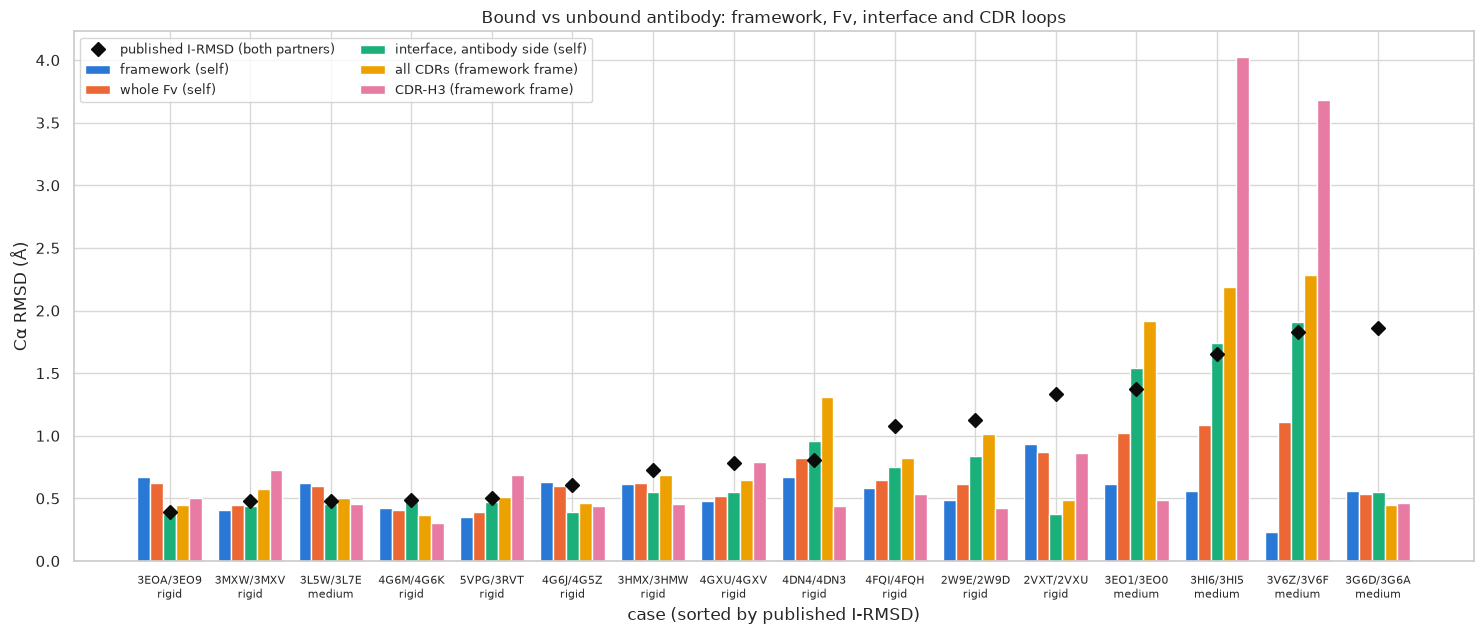

CDR displacement / framework RMSD, per case:
  median 1.37x, range 0.52-9.71x
  CDRs move more than the framework in 10/16 cases
  Wilcoxon signed-rank (CDR vs framework): p = 0.1


In [10]:
BARS = [('framework', 'framework (self)'), ('fv', 'whole Fv (self)'),
        ('interface_ab', 'interface, antibody side (self)'), ('cdr_fw', 'all CDRs (framework frame)'),
        ('H3_fw', 'CDR-H3 (framework frame)')]
x = np.arange(len(summary))
width = 0.16

fig, ax = plt.subplots(figsize=(15, 6.5))
for i, (key, label) in enumerate(BARS):
    ax.bar(x + (i - 2) * width, summary[key], width, label=label, color=ar.SERIES[i],
           edgecolor='white', linewidth=1)
ax.plot(x, summary.benchmark_irmsd, 'D', color=ar.INK, ms=7, label='published I-RMSD (both partners)', zorder=5)
ax.set_xticks(x, [f'{r.ref_code}/{r.unb_code}\n{r.difficulty}' for _, r in summary.iterrows()], fontsize=8)
ax.set(ylabel='Cα RMSD (Å)', xlabel='case (sorted by published I-RMSD)',
       title='Bound vs unbound antibody: framework, Fv, interface and CDR loops')
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig3_per_case_bars.png', dpi=150, bbox_inches='tight')
plt.show()

ratio = summary.cdr_fw / summary.framework
print('CDR displacement / framework RMSD, per case:')
print(f'  median {ratio.median():.2f}x, range {ratio.min():.2f}-{ratio.max():.2f}x')
print(f'  CDRs move more than the framework in {int((ratio > 1).sum())}/{len(ratio)} cases')
print(f'  Wilcoxon signed-rank (CDR vs framework): p = '
      f'{stats.wilcoxon(summary.cdr_fw, summary.framework).pvalue:.2g}')

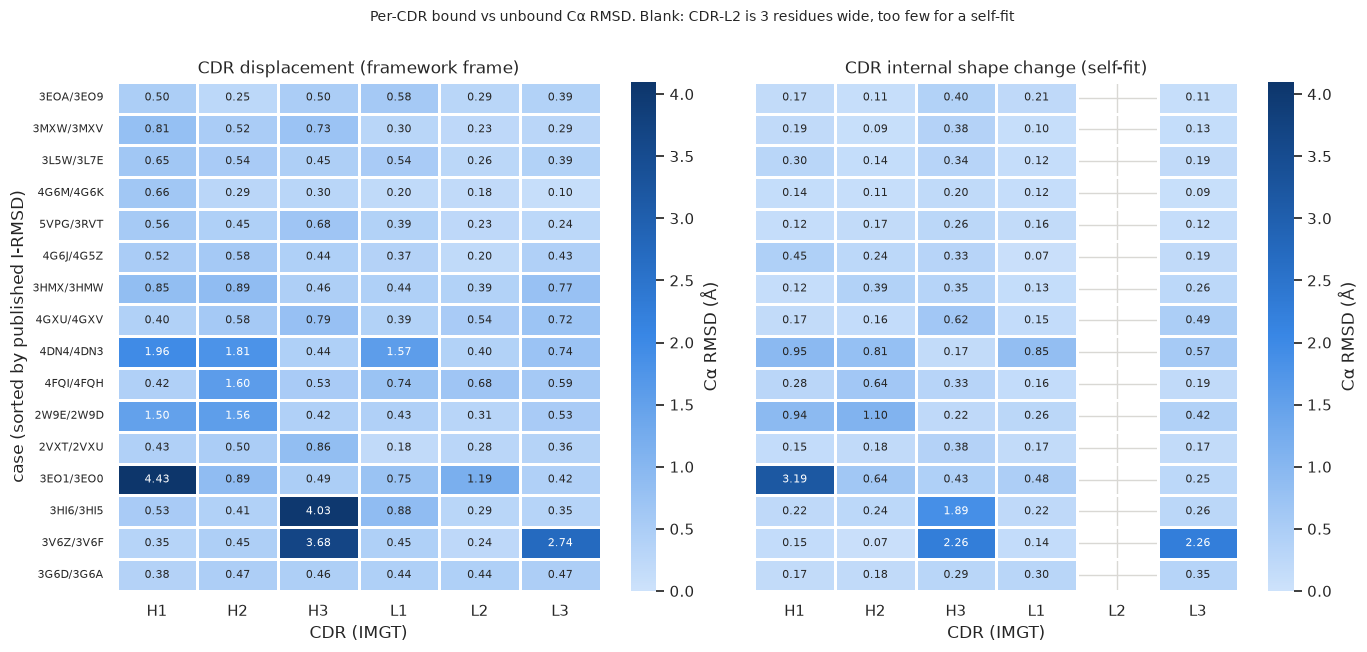

median displacement in the framework frame, per CDR (A):
H1    0.55
H2    0.53
H3    0.49
L1    0.44
L2    0.29
L3    0.43

CDR-H3 is the largest of the six in 5/16 cases
largest single-loop displacements: 3EO1 H1 4.43 A, 3HI6 H3 4.03 A, 3V6Z H3 3.68 A, 3V6Z L3 2.74 A


In [11]:
labels = [f'{r.ref_code}/{r.unb_code}' for _, r in summary.iterrows()]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, scheme, title in zip(axes, ('fv_fw', 'self'),
                             ('displacement (framework frame)', 'internal shape change (self-fit)')):
    mat = pd.DataFrame({c: ar.pick(df, c, scheme) for c in ar.CDRS}).loc[summary.index]
    sns.heatmap(mat, annot=True, fmt='.2f', cmap=ar.BLUES, vmin=0, vmax=4.1, ax=ax,
                cbar_kws={'label': 'Cα RMSD (Å)'}, annot_kws={'fontsize': 8},
                linewidths=1, linecolor='white')
    ax.set(title=f'CDR {title}', xlabel='CDR (IMGT)', ylabel='')
    ax.set_yticks(np.arange(len(labels)) + 0.5, labels, rotation=0, fontsize=8)
axes[0].set_ylabel('case (sorted by published I-RMSD)')
fig.suptitle('Per-CDR bound vs unbound Cα RMSD. Blank: CDR-L2 is 3 residues wide, too few for a self-fit',
             y=1.0, fontsize=10)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig4_cdr_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

per_cdr = pd.DataFrame({c: ar.pick(df, c, 'fv_fw') for c in ar.CDRS})
print('median displacement in the framework frame, per CDR (A):')
print(per_cdr.median().round(2).to_string())
print(f'\nCDR-H3 is the largest of the six in {int((per_cdr.idxmax(axis=1) == "H3").sum())}/16 cases')
top = per_cdr.stack().nlargest(4)
print('largest single-loop displacements:',
      ', '.join(f'{cases.ref_code[i]} {c} {v:.2f} A' for (i, c), v in top.items()))

## 7. Benchmark difficulty

The benchmark classes a case by its I-RMSD (and the change in buried surface), both partners together.
Does the class show up in the antibody alone?

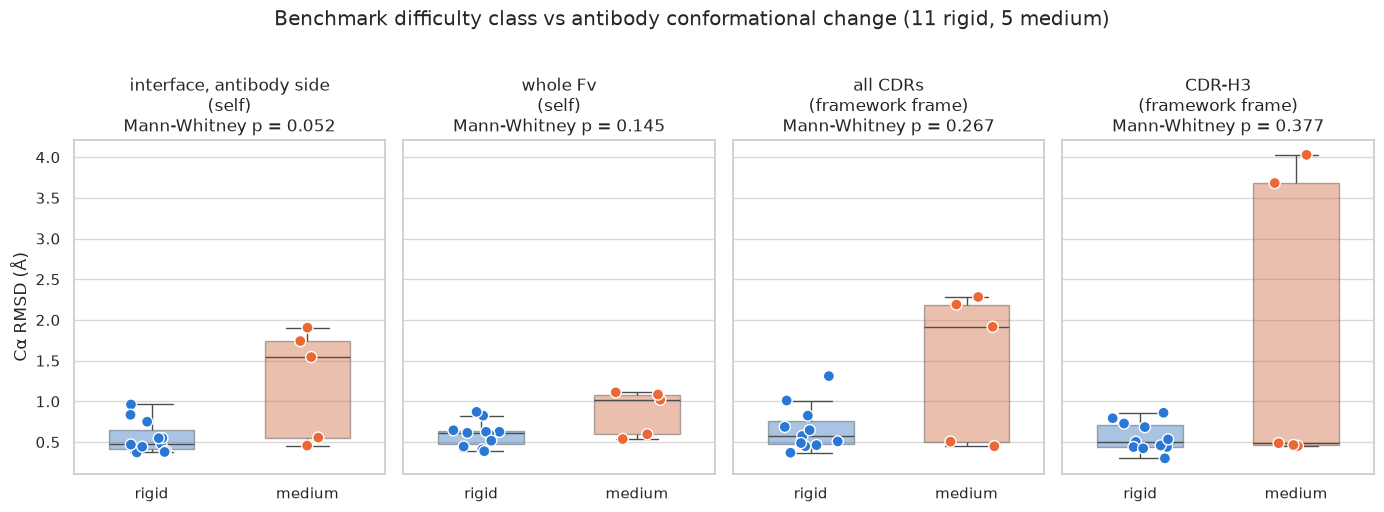

,wf_irmsd_ab,fv,cdr_fw,H3_fw
difficulty,,,,
medium,1.54,1.02,1.92,0.49
rigid,0.48,0.61,0.58,0.50


In [12]:
PANELS = [('wf_irmsd_ab', 'interface, antibody side\n(self)'), ('fv', 'whole Fv\n(self)'),
          ('cdr_fw', 'all CDRs\n(framework frame)'), ('H3_fw', 'CDR-H3\n(framework frame)')]
fig, axes = plt.subplots(1, len(PANELS), figsize=(14, 5), sharey=True)
for ax, (key, label) in zip(axes, PANELS):
    sns.boxplot(data=summary, x='difficulty', y=key, order=['rigid', 'medium'], hue='difficulty',
                legend=False, ax=ax, palette=ar.DIFF_COLOR, width=0.55, showfliers=False,
                boxprops={'alpha': 0.45})
    sns.stripplot(data=summary, x='difficulty', y=key, order=['rigid', 'medium'], hue='difficulty',
                  legend=False, ax=ax, palette=ar.DIFF_COLOR, size=8, edgecolor='white', linewidth=1,
                  jitter=0.18)
    u = stats.mannwhitneyu(summary.loc[summary.difficulty == 'rigid', key],
                           summary.loc[summary.difficulty == 'medium', key], alternative='two-sided')
    ax.set(title=f'{label}\nMann-Whitney p = {u.pvalue:.3f}', xlabel='', ylabel='')
axes[0].set_ylabel('Cα RMSD (Å)')
fig.suptitle('Benchmark difficulty class vs antibody conformational change (11 rigid, 5 medium)', y=1.02)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig5_difficulty_split.png', dpi=150, bbox_inches='tight')
plt.show()
display(summary.groupby('difficulty')[[k for k, _ in PANELS]].median().round(2))

## 8. Why "whole antibody" needs qualifying

`full / self`, a whole-Fab RMSD over every paired residue, is far above the Fv's: the elbow angle between the
variable and the constant modules differs between crystal forms, and one rigid superposition cannot satisfy
both modules. The left panel shows it directly, the Fv measured in a whole-Fab fit against the Fv fitted on
itself. The right panel splits the CDR motion: height above the diagonal is displacement a rigid re-placement
of the loops would absorb; position along it is change of loop shape.

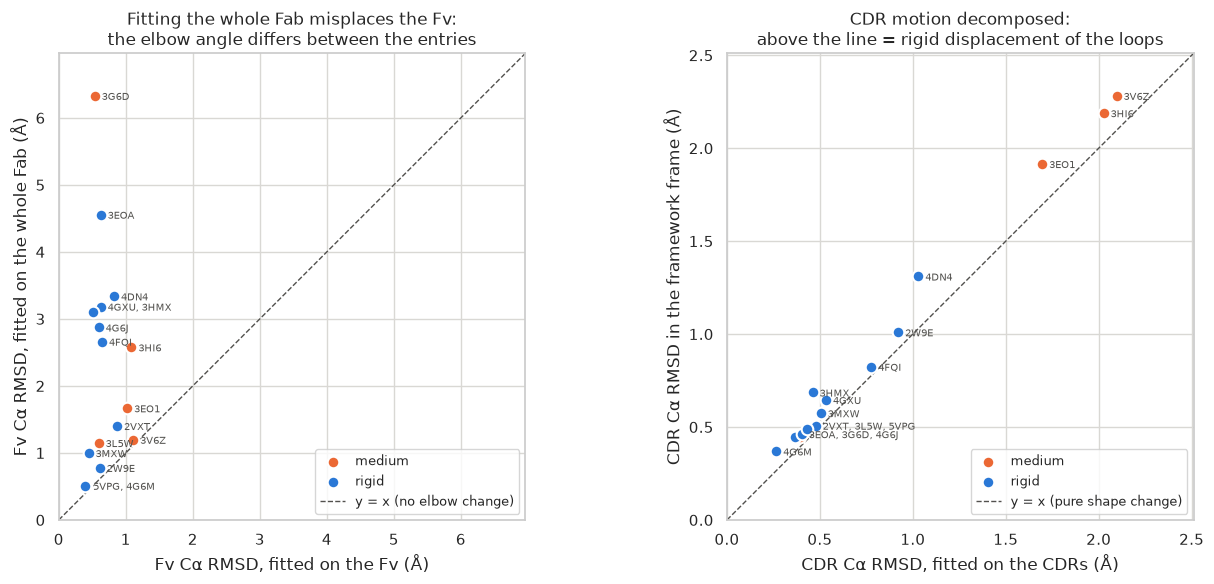

whole-Fab RMSD (full/self)   : 0.51 - 7.01 A (median 2.53)
whole-Fv RMSD (fv/self)      : 0.39 - 1.11 A (median 0.62)
Fv residual in a whole-Fab fit: 0.51 - 6.33 A (median 2.12)
the whole-Fab fit inflates the Fv RMSD by more than 50% in 12/16 cases


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 6))
for ax, xkey, ykey in ((ax1, 'fv', 'fv_in_full'), (ax2, 'cdr_self', 'cdr_fw')):
    for diff, grp in summary.groupby('difficulty'):
        ax.scatter(grp[xkey], grp[ykey], s=70, color=ar.DIFF_COLOR[diff], edgecolor='white',
                   linewidth=1.5, label=diff, zorder=3)
    ar.label_points(ax, summary[xkey], summary[ykey], summary.ref_code)
    lim = 1.1 * max(summary[xkey].max(), summary[ykey].max())
    ax.plot([0, lim], [0, lim], ls='--', color=ar.INK_MUTED, lw=1, zorder=1)
    ax.set(xlim=(0, lim), ylim=(0, lim), aspect='equal')
ax1.plot([], [], ls='--', color=ar.INK_MUTED, lw=1, label='y = x (no elbow change)')
ax2.plot([], [], ls='--', color=ar.INK_MUTED, lw=1, label='y = x (pure shape change)')
ax1.set(xlabel='Fv Cα RMSD, fitted on the Fv (Å)', ylabel='Fv Cα RMSD, fitted on the whole Fab (Å)',
        title='Fitting the whole Fab misplaces the Fv:\nthe elbow angle differs between the entries')
ax2.set(xlabel='CDR Cα RMSD, fitted on the CDRs (Å)', ylabel='CDR Cα RMSD in the framework frame (Å)',
        title='CDR motion decomposed:\nabove the line = rigid displacement of the loops')
for ax in (ax1, ax2):
    ax.legend(loc='lower right', fontsize=9)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig6_elbow_and_decomposition.png', dpi=150, bbox_inches='tight')
plt.show()

for key, label in (('full', 'whole-Fab RMSD (full/self)   '), ('fv', 'whole-Fv RMSD (fv/self)      '),
                   ('fv_in_full', 'Fv residual in a whole-Fab fit')):
    print(f'{label}: {summary[key].min():.2f} - {summary[key].max():.2f} A (median {summary[key].median():.2f})')
print(f'the whole-Fab fit inflates the Fv RMSD by more than 50% in '
      f'{int((summary.fv_in_full > 1.5 * summary.fv).sum())}/16 cases')

## 9. The largest CDR-H3 displacement, superposed

The unbound antibody is placed on the bound one by its **Fv framework Cα only**, and nothing is refitted, so
the viewer shows the actual displacement of the loop, not a best fit of the loop onto itself. Both files are
the prepared ones (chain A, numbered from 1), so the loop is selected by the residues the IMGT ranges
resolved to.

largest CDR-H3 displacement: case 13, 3HI6_XY:B (bound) vs 3HI5_HL (unbound) = 4.03 A Ca RMSD
fitted on 179 framework Ca (no CDR atom takes part in the fit)
superposed unbound antibody: /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/worst_H3_3HI5_on_3HI6.pdb


,resname,resid_bound,resid_unbound,in_interface,Ca displacement (A)
imgt,,,,,
105,ALA,97,96,False,0.41
106,SER,98,97,True,0.68
107,SER,99,98,True,2.59
108,TYR,100,99,True,4.78
109,ASP,101,100,True,4.13
110,PHE,102,101,True,3.61
111,TRP,103,102,True,8.13
112,SER,104,103,True,7.01
113,ASN,105,104,True,4.89


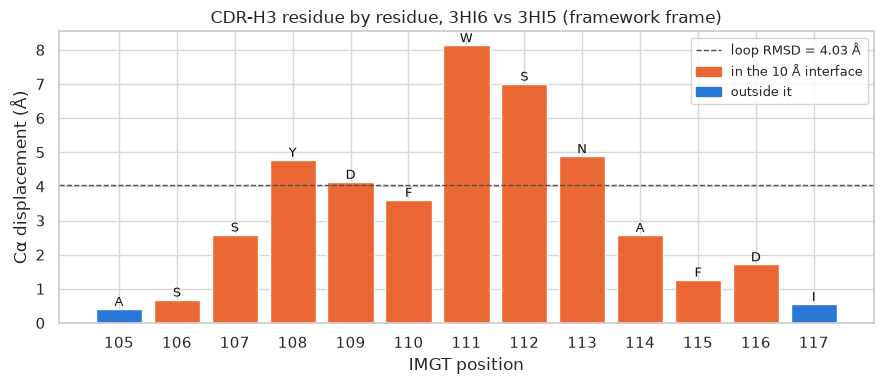

the loop tip moves furthest: IMGT 111 TRP at 8.13 A; its anchors (IMGT 105 and 117) stay within 0.55 A
11/13 loop residues are in the 10 A interface


In [14]:
worst_idx = int(ar.pick(df, 'H3', 'fv_fw').idxmax())
worst, worst_ab = files[worst_idx], ab[worst_idx]
print(f'largest CDR-H3 displacement: case {worst_idx}, {cases.reference[worst_idx]} (bound) vs '
      f'{cases.antibody[worst_idx]} (unbound) = {summary.H3_fw[worst_idx]:.2f} A Ca RMSD')
print(f"fitted on {len(worst_ab['extents']['framework'])} framework Ca (no CDR atom takes part in the fit)")
super_pdb = ar.write_superposed(worst, worst_ab['frames']['fv_fw'],
                                ar.OUT / f'worst_H3_{cases.unb_code[worst_idx]}_on_{cases.ref_code[worst_idx]}.pdb')
print('superposed unbound antibody:', super_pdb)

h3 = dfres[(dfres.case_idx == worst_idx) & (dfres.region == 'H3')].sort_values('resid_unbound')
display(h3[['imgt', 'resname', 'resid_bound', 'resid_unbound', 'in_interface', 'dev_ca_fv_fw']]
        .rename(columns={'dev_ca_fv_fw': 'Ca displacement (A)'}).round(2).set_index('imgt'))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(h3.imgt, h3.dev_ca_fv_fw, color=[ar.SERIES[1] if i else ar.SERIES[0] for i in h3.in_interface],
       edgecolor='white', linewidth=1)
for i, (dev, name) in enumerate(zip(h3.dev_ca_fv_fw, h3.resname)):
    ax.annotate(seq1(name), (i, dev), ha='center', va='bottom', fontsize=9, color=ar.INK)
ax.axhline(summary.H3_fw[worst_idx], ls='--', color=ar.INK_MUTED, lw=1,
           label=f'loop RMSD = {summary.H3_fw[worst_idx]:.2f} Å')
handles = [Patch(color=ar.SERIES[1], label='in the 10 Å interface'), Patch(color=ar.SERIES[0], label='outside it')]
ax.set(xlabel='IMGT position', ylabel='Cα displacement (Å)',
       title=f'CDR-H3 residue by residue, {cases.ref_code[worst_idx]} vs {cases.unb_code[worst_idx]} '
             '(framework frame)')
ax.legend(handles=ax.get_legend_handles_labels()[0] + handles, fontsize=9)
fig.tight_layout()
fig.savefig(ar.FIG / 'fig7_worst_h3_profile.png', dpi=150, bbox_inches='tight')
plt.show()

tip = h3.loc[h3.dev_ca_fv_fw.idxmax()]
print(f'the loop tip moves furthest: IMGT {tip.imgt} {tip.resname} at {tip.dev_ca_fv_fw:.2f} A; its anchors '
      f'(IMGT {h3.imgt.iloc[0]} and {h3.imgt.iloc[-1]}) stay within '
      f'{max(h3.dev_ca_fv_fw.iloc[0], h3.dev_ca_fv_fw.iloc[-1]):.2f} A')
print(f'{int(h3.in_interface.sum())}/{len(h3)} loop residues are in the 10 A interface')

In [15]:
# blue cartoon = bound Fv,  grey cartoon = unbound Fv (superposed),  faint = antigen
# green sticks = bound CDR-H3,  orange sticks = unbound CDR-H3
sel_bound, sel_unbound = ar.ngl_selection(h3.resid_bound), ar.ngl_selection(h3.resid_unbound)
fv = worst_ab['extents']['fv']
view = nv.NGLWidget()
bound = view.add_component(worst['reference'], name=f'{cases.ref_code[worst_idx]} bound')
unbound = view.add_component(super_pdb, name=f'{cases.unb_code[worst_idx]} unbound (superposed)')
view.clear_representations(component=0)
view.clear_representations(component=1)
bound.add_cartoon(selection=ar.ngl_selection([worst_ab['pairs'][u] for u in fv]), color='#6da7ec', opacity=0.3)
bound.add_cartoon(selection=':B', color='#b0b0b0', opacity=0.15)
unbound.add_cartoon(selection=ar.ngl_selection(fv), color='#9a9a9a', opacity=0.3)
for comp, sel, color in ((bound, sel_bound, '#1baf7a'), (unbound, sel_unbound, '#eb6834')):
    comp.add_cartoon(selection=sel, color=color, aspectRatio=2.0, scale=1.4)
    comp.add_ball_and_stick(selection=sel, color=color, aspectRatio=1.6)
bound.add_spacefill(selection=f'{tip.resid_bound}:A and .CA', color='#1baf7a', radius=0.9)
unbound.add_spacefill(selection=f'{tip.resid_unbound}:A and .CA', color='#eb6834', radius=0.9)
view.add_label(selection=f'{tip.resid_bound}:A and .CA', component=0, labelType='format',
               labelFormat=f'{seq1(tip.resname)}{tip.imgt} ({tip.dev_ca_fv_fw:.1f} Å)',
               color='#111111', radius=2.2)
view.center(selection=sel_bound, component=0)
view._set_size('100%', '600px')
view

NGLWidget()

## 10. Findings

**1. The benchmark's definition is reproduced exactly.** On the benchmark's own files, the I-RMSD as defined
(10 Å any-atom interface, each partner fitted on the Cα of its own interface residues, both pooled) equals the
published value within 0.01 Å in 15 of 16 cases; 4G6M reads 0.52 Å against 0.49. The published column is
now computed rather than correlated with (the antibody-only stand-in of the previous version reached
Pearson *r* = 0.67), so the cutoff sweep and the 5 Å interface have nothing left to decide. `haddock_interface`
at 10 Å lists exactly the any-atom interface in all 16 cases.

**2. The workflow's structures are the benchmark's in 13 of 16 cases.** The assembly download, the Modeller
repair (no repaired residue falls in any interface) and steps 1_0–1_6 give the same I-RMSD as the benchmark
files within 0.01 Å, except:

* **4GXU/4GXV: 8.63 Å vs 0.78 Å, and 4FQI/4FQH: 2.13 vs 1.08 Å.** Both antigens are HA trimers.
  `prepare_antigen` fuses the antigen chains in file order and `map_contact_residues` pairs the fused chains
  position by position, so the protomers are paired by their order in the files. 4GXU lists them A–F and
  1RUZ H–M, while the benchmark (and the identifiers' `ABEFCD` ↔ `HIJKLM`) pairs C/D with L/M; 4FQI's assembly
  holds three identical A/B copies. The 10 Å interface reaches a second protomer (17 residues on chain E in
  4GXU, 1 in 4FQI), and those residues are carried onto the wrong one. Stage 1's own 3.9 Å epitope lies on a
  single protomer in both (A in 4GXU, A + B of one copy in 4FQI), so **the docking restraints are not
  affected**; anything that pairs antigen residues across protomers is.
* **2VXT/2VXU: 1.40 vs 1.32 Å**, antigen side only (2.13 vs 2.00 Å). 1J0S is an NMR entry: the benchmark's
  unbound antigen is its model 6 (0.00 Å Cα RMSD), the workflow downloads model 1 (1.40 Å from model 6).
  `launch_wf.py` already names the model for 1IK0 (`1IK0_A(10)`, `(11)`), not for 1J0S.

**3. In most cases the antigen carries more of the I-RMSD than the antibody.** The antigen side is the larger
in 12 of 16 cases. 3G6D, the largest published value (1.86 Å), is all antigen: antibody 0.55 Å, antigen
2.88 Å (the NMR antigen 1IK0); 2VXT likewise (0.38 vs 2.00 Å). The previous version could only suspect this.
Of the five *medium* cases, 3EO1, 3HI6 and 3V6Z are antibody-driven (1.5–1.9 Å on the antibody side), 3G6D is
antigen-driven, and 3L5W (0.48 Å) is classed medium by criteria other than the I-RMSD.

**4. "RMSD of the whole antibody" is the Fab elbow.** Over every paired residue the whole-Fab Cα RMSD is
0.51–7.01 Å (median 2.53 Å), the Fv 0.39–1.11 Å (median 0.62 Å); a whole-Fab fit inflates the Fv RMSD by more
than 50 % in 12 of 16 cases. The Fv is the meaningful global measure for anything to do with binding.

**5. CDR loops move more than the framework, modestly.** In the Fv-framework frame the CDRs move 1.37× the
framework RMSD (median; 0.52–9.71×), more in 10 of 16 cases (Wilcoxon *p* = 0.10).

**6. CDR-H3 owns the extremes, not the median.** Median displacement per CDR: H1 0.55, H2 0.53, H3 0.49,
L1 0.44, L3 0.43, L2 0.29 Å; H3 is the largest of the six in 5 of 16 cases. The largest single loops are
3EO1 H1 (4.43 Å), 3HI6 H3 (4.03 Å), 3V6Z H3 (3.68 Å) and 3V6Z L3 (2.74 Å). 3HI6's H3 moves as a hinge: its
anchors (IMGT 105, 117) stay within 0.55 Å while the tip, Trp111, moves 8.13 Å, and 11 of its 13 residues are
in the 10 Å interface.

**7. The difficulty class shows in the antibody's interface.** Median antibody-side interface RMSD is 1.54 Å
for the medium cases against 0.48 Å for the rigid ones (Mann-Whitney *p* = 0.052; 5 vs 11 cases).

### For the AWH work

Ranked by CDR displacement in the framework frame, enhanced sampling of the loops has most to recover in
**3V6Z (2.28 Å), 3HI6 (2.19 Å), 3EO1 (1.92 Å)**, then 4DN4 (1.31 Å) and 2W9E (1.01 Å). At the other end,
**4G6M (0.37 Å), 3EOA (0.45 Å), 3G6D (0.45 Å), 4G6J (0.46 Å), 2VXT (0.49 Å)**: the unbound antibody is already
in its bound conformation, and in 3G6D and 2VXT what the docking has to absorb is the antigen.
`results/ab_rmsds_summary.csv` holds the per-case numbers to correlate with docking quality.

### Compared with the previous version

* The I-RMSD covers both partners and reproduces the published column (finding 1).
* Residues are paired by sequence on the repaired structures instead of by IMGT position, which mispaired a
  few residues where ANARCII numbered the bound and unbound chains differently: 2VXT light-chain IMGT 10
  (3.74 → 0.29 Å), 3V6Z H58, H59 and H93 (about 4 Å → under 0.5 Å; the repair also rebuilt the residue missing
  from 3V6F). 3V6Z's framework RMSD goes from 0.37 to 0.24 Å and its CDR displacement from 2.44 to 2.28 Å.
* Light-chain IMGT 128, the residue at the junction with CL, is now paired. It follows the elbow (5.3 Å off
  in 3EOA, 4.5 Å in 3G6D) and raises the framework RMSD of the two largest-elbow cases (3EOA 0.53 → 0.67 Å,
  3G6D 0.45 → 0.56 Å), which is why the CDR-vs-framework Wilcoxon went from *p* = 0.04 to 0.10.

### Caveats

* The workflow I-RMSD of 4FQI and 4GXU measures the protomer pairing, not a conformational change (finding 2).
* The workflow's reference for the 3RVT case is 5VPG, the benchmark's is 3RVW; both give 0.50 Å.
* `cdr.FRAMEWORK_RANGES` runs to IMGT 129, the first CH1/CL residue; it is clipped at 128 here (see section
  4). Stages 2 and 3 build their framework groups from the unclipped ranges.
* CDR-L2 is 3 residues wide, so it has no `self` value.
* `full` covers the residues paired between the two structures; the repair built 1–5 of them in 3HMX, 4DN4,
  3L5W and 3V6Z, none in an interface.

### Outputs

| file | content |
|---|---|
| `output/exploration/rmsds/results/ab_rmsds_irmsd.csv` | I-RMSD per case: published, benchmark files, workflow, and the two sides of each |
| `output/exploration/rmsds/results/ab_rmsds_summary.csv` | headline table, one row per case |
| `output/exploration/rmsds/results/ab_rmsds_long.csv` | every extent × scheme × case, Cα |
| `output/exploration/rmsds/results/ab_rmsds_residues.csv` | per-residue Cα displacement in the framework frame, IMGT position, region, interface flag |
| `output/exploration/rmsds/figures/*.png` | figures 1–7 |
| `output/exploration/rmsds/worst_H3_*.pdb` | unbound antibody superposed on the bound one by its Fv framework Cα |
| `output/exploration/rmsds/prep/case_<i>/` | the workflow's configuration and prepared structures; `benchmark/` holds the control |
| `output/exploration/rmsds/previous/` | the previous version of this analysis |